In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import h5py
# import fast_calc

# FIGURE_WIDTH_1COL = 3.404  # For PRX style, change for according to journal
# FIGURE_WIDTH_2COL = 7.057  # For PRX style, change for according to journal
# FIGURE_HEIGHT_1COL_GR = FIGURE_WIDTH_1COL*2/(1 + np.sqrt(5))
# FIGURE_HEIGHT_2COL_GR = FIGURE_WIDTH_2COL*2/(1 + np.sqrt(5))
# 
# font_size = 6 # For PRX style, change for according to journal
# 
# plt.rcParams.update({
#     'font.size'           : font_size,  
#     'figure.titlesize'    : 'medium',
#     'figure.dpi'          : 1000, # 1000
#     'figure.figsize'      : (FIGURE_WIDTH_1COL, FIGURE_HEIGHT_1COL_GR),
#     'axes.titlesize'      : 'medium',
#     'axes.axisbelow'      : True,
#     'xtick.direction'     : 'in',
#     'xtick.labelsize'     : 'small',
#     'ytick.direction'     : 'in',
#     'ytick.labelsize'     : 'small',
#     'image.interpolation' : 'none',
#     'legend.fontsize'     : font_size,
#     'axes.labelsize'      : font_size,
#     'axes.titlesize'      : font_size,
#     'xtick.labelsize'     : font_size,
#     'ytick.labelsize'     : font_size,
# })
# 
# 
# plt.rcParams.update({'font.family':'sans-serif'})

In [2]:
# help(fast_calc.createFullHamiltonian)
# help(fast_calc.createHamiltonian)

In [ ]:
N = 10
L = [10, 10, 4]
N_tot = np.prod(L)
t = 1.0
t_z = -1.0
m_z = 0.0
t_0 = 1.0
w = 0.0
disorder_type = "uniform"
Ns = 100
# disorder_array = np.zeros((2*N_tot, 2*N_tot), dtype=complex)

# H1 = fast_calc.createFullHamiltonian(L, t, t_z, m_z, t_0, w, disorder_array, "uniform")
# disorder_array = np.zeros((2*N, 2*N), dtype=complex)
# H2 = fast_calc.createHamiltonian(L, t, t_z, m_z, t_0, w, disorder_array, "uniform", True)
# Last input tunes whether x-OBC/PBC everything else stays PBC


In [5]:
from itertools import product
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
# H = np.zeros((L[2]*L[1], 2*L[0], 2*L[0]), dtype=complex)
H = np.zeros((2*N_tot, 2*N_tot), dtype=complex)
for z in range(L[2]):
    for y in range(L[1]):
        for x in range(L[0]):
            submatrix = t*np.sin(2*np.pi*x/L[0])*X + t*np.sin(2*np.pi*y/L[1])*Y + (t_z*np.cos(2*np.pi*z/L[2]) - m_z + t_0*(2-np.cos(2*np.pi*x/L[0])-np.cos(2*np.pi*y/L[1])))*Z
            # H[np.array([[y+L[1]*z, y+L[1]*z], [y+L[1]*z, y+L[1]*z]]), np.array([[0, 0], [1, 1]])+2*x, np.array([[0, 1], [0, 1]])+2*x] = submatrix
            H[np.array([[0, 0], [1, 1]])+2*(x + L[0]*(y + L[1]*z)), np.array([[0, 1], [0, 1]])+2*(x + L[0]*(y + L[1]*z))] = submatrix


def transformation_matrix(N):
    transformation_matrix = np.zeros((N, N), dtype=complex)
    for i in range(N):
        for j in range(N):
            transformation_matrix[i, j] = np.exp(-2j*np.pi*i*j/N)/np.sqrt(N)
    return transformation_matrix
print("is unitary:", np.allclose(transformation_matrix(L[2])@transformation_matrix(L[2]).conj().T, np.eye(L[2]), atol=1e-10))
# H_new = H
# transform = np.kron(transformation_matrix(L[0]), np.eye(2, dtype=complex))
# for z in range(L[2]):
#     for y in range(L[1]):
#         H[y+L[1]*z, :, :] = transform.conj().T @ H[y+L[1]*z, :, :] @ transform
# H_new = H
H_new = np.kron(transformation_matrix(L[2]), np.kron(transformation_matrix(L[1]), np.kron(transformation_matrix(L[0]), np.eye(2, dtype=complex)))).conj().T @ H @ np.kron(transformation_matrix(L[2]), np.kron(transformation_matrix(L[1]), np.kron(transformation_matrix(L[0]), np.eye(2, dtype=complex))))
# H_new1 = H_new.copy()
# for s, x, y, z in product(range(2), range(L[0]), range(L[1]), range(L[2])):
#     i = s + 2*(x + L[0]*(y + L[1]*z))
#     if x == N-1:
#         H_new[i, (s + 1) %
#         2 + 2*(0 + L[0]*(y + L[1]*z))] -= -t/2*1j
#         H_new[(s + 1) %
#         2 + 2*(0 + L[0]*(y + L[1]*z)), i] -= t/2*1j
#         H_new[i, s + 2*(0 + L[0]*(y + L[1]*z))
#         ] -= -t_0/2*(-1)**s
#         H_new[s + 2*(0 + L[0]*(y + L[1]*z)), i] -= -t_0/2*(-1)**s
# 
#         H_new1[i, (s + 1) %
#         2 + 2*(0 + L[0]*(y + L[1]*z))] = 0
#         H_new1[(s + 1) %
#         2 + 2*(0 + L[0]*(y + L[1]*z)), i] = 0
#         H_new1[i, s + 2*(0 + L[0]*(y + L[1]*z))
#         ] = 0
#         H_new1[s + 2*(0 + L[0]*(y + L[1]*z)), i] = 0
#     if y == N-1:
#         H_new[i, (s + 1) % 2 + 2*(x + L[0]*(0 + L[1]*z))
#         ] -= -t/2*(-1)**s
#         H_new[(s + 1) % 2 + 2*(x + L[0]*(0 + L[1]*z)), i] -= -t/2*(-1)**s
#         H_new[i, s + 2*(x + L[0]*(0 + L[1]*z))
#         ] -= -t_0/2*(-1)**s
#         H_new[s + 2*(x + L[0]*(0 + L[1]*z)), i] -= -t_0/2*(-1)**s
# 
#         H_new1[i, (s + 1) % 2 + 2*(x + L[0]*(0 + L[1]*z))
#         ] = 0
#         H_new1[(s + 1) % 2 + 2*(x + L[0]*(0 + L[1]*z)), i] = 0
#         H_new1[i, s + 2*(x + L[0]*(0 + L[1]*z))
#         ] = 0
#         H_new1[s + 2*(x + L[0]*(0 + L[1]*z)), i] = 0
#     if z == N-1:
#         H_new[i, s + 2*(x + L[0]*(y + 0))
#         ] -= t_z/2*(-1)**s
#         H_new[s + 2*(x + L[0]*(y + 0)), i] -= t_z/2*(-1)**s
# 
#         H_new1[i, s + 2*(x + L[0]*(y + 0))
#         ] = 0
#         H_new1[s + 2*(x + L[0]*(y + 0)), i] = 0

# plt.plot(np.sort(np.linalg.eigvalsh(H).flatten()))
# plt.plot(np.sort(np.linalg.eigvalsh(H_new).flatten()))
# plt.plot(np.sort(np.linalg.eigvalsh(H1).flatten()))
# plt.plot(np.sort(np.linalg.eigvalsh(H2).flatten()))
# plt.show()
# print(np.sort(np.linalg.eigvalsh(H_new).flatten()))

is unitary: True


  0%|          | 0/2 [00:00<?, ?it/s]

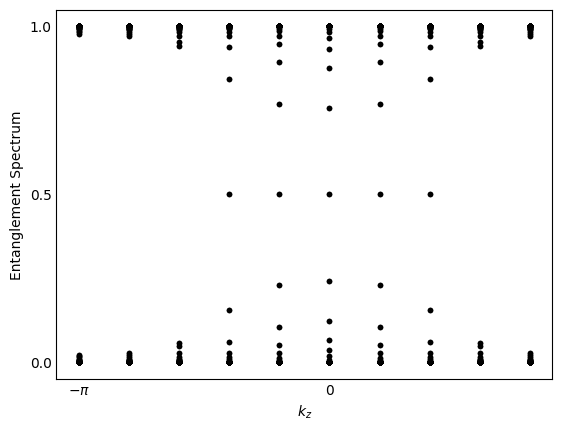

  0%|          | 0/2 [00:06<?, ?it/s]


AssertionError: 

In [ ]:
from scipy.optimize import brentq

def compute_ipr(eigvecs):
    # return np.sum(np.abs(eigvecs)**4, axis=0)
    result = np.sum((np.abs(eigvecs)**2).reshape(L[1]*L[2], L[0]//2, 2, -1), axis=(0, 2))
    return np.sum(result**2, axis=0)

def compute_boundary_occupation(eigvecs):
    indices = np.arange(L[0]*L[1]*L[2])
    s = indices % 2
    x = (indices // 2) % (L[0]//2)
    y = (indices // L[0]) % L[1]
    z = indices // (L[0] * L[1])
    
    # boundary = any coordinate on the edge
    is_boundary = (x < 1) | (x >= L[0]-1)
    
    boundary_indices = np.where(is_boundary)[0]
    return np.sum(np.abs(eigvecs[boundary_indices, :])**2, axis=0)

from datetime import datetime
def plot_boundary_occupation(eigvecs):
    # reshaped = np.sum((np.abs(eigvecs)**2).reshape(N**2, N//2, 2, -1), axis=(0, 2))
    # for i in range(reshaped.shape[1]):
    #     plt.plot(reshaped[:, i], label=f"Eigenstate {i}", marker=".", linestyle="None")
    #     plt.show()
    value = np.mean((np.abs(eigvecs)**2).reshape(L[1]*L[2], L[0]//2, 2, -1).swapaxes(0, 1).reshape(L[0]//2, 2*L[1]*L[2], -1), axis=-1)/np.sum(np.mean((np.abs(eigvecs)**2).reshape(L[1]*L[2], L[0]//2, 2, -1).swapaxes(0, 1).reshape(L[0]//2, 2*L[1]*L[2], -1), axis=-1), axis=0, keepdims=True)
    plt.plot(value, label="Total", marker=".", linestyle="None", color=color)
    plt.plot(np.mean(value, axis=1), color="red")
    plt.xlabel("x")
    plt.ylabel("Occupation")
    plt.axhline(0, color="black", linestyle="--", alpha=0.5)
    plt.axhline(0.5, color="black", linestyle="--", alpha=0.5)
    plt.ylim(-0.05, 0.55)
    plt.title(f"w={w}, filling={N_tot/(2*N_tot):.3f}")
    # plt.legend()
    # Save with datetime stamp

    # plt.savefig(datetime.now().strftime("boundary_occupation_%Y%m%d-%H%M%S.pdf"), bbox_inches='tight')
    plt.show()
    plt.close()
    return np.mean(value, axis=1)[2]

def compute_magnetization(eigvecs):
    return np.sum(np.abs(eigvecs[::2])**2, axis=0) - np.sum(np.abs(eigvecs[1::2])**2, axis=0)


def fermi(eps, mu, beta):
    x = beta * (eps - mu)
    # numerically stable version
    return np.where(x > 0, np.exp(-x)/(1 + np.exp(-x)), 1/(1 + np.exp(x)))

def filling(mu, eps, beta):
    return np.sum(fermi(eps, mu, beta))

def find_mu(eps, beta, n_target):
    def F(mu):
        results = filling(mu, eps, beta) - n_target
        return results

    # bracket safely
    mu_lo = np.min(eps) - 10.0 / beta
    mu_hi = np.max(eps) + 10.0 / beta

    return brentq(F, mu_lo, mu_hi)

def compute_entropy(eigvals):
    entropy = np.zeros_like(eigvals)
    for i, val in enumerate(eigvals):
        if val < 1e-10 or val > 1-1e-10:
            entropy[i] = 0
        else:
            entropy[i] = -val*np.log2(val)-(1-val)*np.log2(1-val)
    return entropy

color = "#ACACAC"
color = '#000000'

# w_array = np.arange(3.0, 4.6, 0.1)
# w_array = np.linspace(3.5, 4.0, 11)
# w_array = [4.8]
# w_array = np.array([1, 2, 3, 3.8, 4.4])
# w_array = np.array([0, 2.0])
w_array = np.linspace(0, 5.0, 51)
Ns = 1
beta = 10
all_ent_diffs = np.zeros((Ns, len(w_array)))
all_ent_diffsprime = np.zeros((Ns, len(w_array)))
gaps = []
ES_gaps = []
eigvals_total = []
eigvecs_total = []
all_combined_states = []
quick_eigvals = []
for j, w in tqdm(enumerate(w_array), total=len(w_array)):
    filtered = np.zeros((N_tot, 10*Ns), dtype=complex)
    all_eigvals = []
    all_eigvecs = []
    all_filtered_eigvecs = []
    for n in range(Ns):
        all_ents = []
        H_curr = H_new + np.kron(np.eye(L[1]*L[2], dtype=complex), np.kron(w*np.diag(np.random.random(L[0])), np.eye(2)))# + np.kron(w*np.diag(np.random.random(N_tot)), np.eye(2))
        E, V = np.linalg.eigh(H_curr)
        indices = np.abs(E)<1e-4
        # Seems ok for x-OBC
        # zero_eigvecs = np.abs(V[:, indices].reshape(N**2, N, 2, -1)**2).sum(axis=(0, 2))
        # print(zero_eigvecs.shape)
        # plt.plot(zero_eigvecs, ".")
        # plt.show()
        # all_V_new = np.array([V[(np.abs((np.arange(2*N**3)%(2*N))//2 - N/2 + 1/2) < 1) & (np.abs((np.arange(2*N**3)%(2*N**2))//(2*N) - N/2 + 1/2) < 1), :][:, :i] for i in range(1, 2*N**3+1)])
        # print(all_V_new.shape)
        # V_new1 = V[(np.abs((np.arange(2*N**3)%(2*N))//2 - N/2 + 1/2) < 1) & (np.abs((np.arange(2*N**3)%(2*N**2))//(2*N) - N/2 + 1/2) < 1), :][:, :N**3+1]
        # V_new0 = V[(np.abs((np.arange(2*N**3)%(2*N))//2 - N/2 + 1/2) < 1) & (np.abs((np.arange(2*N**3)%(2*N**2))//(2*N) - N/2 + 1/2) < 1), :][:, :N**3]
        # V_new1prime = V[(np.abs((np.arange(2*N**3)%(2*N))//2 - N/2 + 1/2) < 1) & (np.abs((np.arange(2*N**3)%(2*N**2))//(2*N) - N/2 + 1/2) < 1), :][:, :N**3-1]
        for i in range(N_tot, N_tot+1):
            mu = find_mu(E, beta, i)
            # V_new = V[(np.abs((np.arange(2*N**3)%(2*N))//2 - N/2 + 1/2) < 1) & (np.abs((np.arange(2*N**3)%(2*N**2))//(2*N) - N/2 + 1/2) < 1), :][:, :i]
            # V_new = V[(np.abs((np.arange(2*N**3)%(2*N))//2 - N/2 + 1/2) < 1), :][:, :i]
            V_new = V[((np.arange(2*N_tot)%(2*L[0]))//2 < L[0]//2), :][:, :i]
            almost_C = np.einsum("jk, mk->jm", V_new.conj(), V_new)
            C = np.einsum("ijik->ijk", almost_C.reshape(L[1]*L[2], L[0], L[1]*L[2], L[0])).reshape(L[2], L[1], L[0], L[0])
            eigvals, eigvecs = np.linalg.eigh(C)
            # eigvals, eigvecs = np.linalg.eigh(np.einsum("jk, mk->jm", V_new.conj(), V_new))
            plt.plot(np.roll(eigvals.reshape(L[2], -1), L[2]//2, axis=0), ".", color=color)
            plt.xlabel(r"$k_z$")
            plt.ylabel("Entanglement Spectrum")
            plt.yticks([0.0, 0.5, 1.0])
            plt.xticks([0, L[2]//2], [r"$-\pi$", "0"])
            plt.gca().tick_params(axis='both', length=0)
            plt.savefig('entanglement_spectrum_1b.pdf', bbox_inches='tight')
            plt.show()
            with h5py.File('entanglment_spectrum_1b.h5', 'w') as f:
                f.create_dataset('eigvals', data=eigvals)

            assert False

            # all_eigvals.append(np.sort(eigvals.flatten()))

            ES_gaps.append(np.sort(eigvals.flatten())[N_tot//2+5] - np.sort(eigvals.flatten())[N_tot//2+4])

            filtered[:, 10*n:10*(n+1)] = eigvecs[:, N_tot//2-5:N_tot//2+5]
            all_eigvals.append(eigvals)
            all_eigvecs.append(eigvecs)

            entropy = compute_entropy(eigvals.flatten())

            min_entropy = 0.8

            eigvals_filtered = eigvals.flatten()[(entropy>min_entropy)]
            eigvecs_filtered = eigvecs[:, (entropy>min_entropy)]
            entropy_filtered = entropy[(entropy>min_entropy)]
            all_filtered_eigvecs.append(eigvecs[:, N_tot//2-5:N_tot//2+5])

            quick_eigvals.append(eigvals)


            # plt.semilogy(entropy, compute_ipr(eigvecs), ".")
            # plt.axhline(1/L[0], color="black", linestyle="--", alpha=0.5)
            # plt.xlabel("Entropy")
            # # plt.xlabel("Eigenstate index")
            # plt.ylabel("IPR")
            # plt.title(f"w={w}, filling={i/(2*N_tot):.3f}")
            # plt.ylim(1e-1, 1.1)
            # plt.show()
            # plt.plot(entropy, compute_magnetization(eigvecs), ".")
            # plt.xlabel("Entropy")
            # # plt.xlabel("Eigenstate index")
            # plt.ylabel("Magnetization")   
            # plt.title(f"w={w}, filling={i/(2*N_tot):.3f}")
            # plt.ylim(-1.1, 1.1)
            # plt.show()
            # print("Boundary states: ", np.sum(compute_boundary_occupation(eigvecs_filtered).flatten()>0))
            # plt.semilogy(entropy_filtered, compute_boundary_occupation(eigvecs_filtered), ".")
            # plt.axhline(2/L[0], color="black", linestyle="--", alpha=0.5)
            # plt.xlabel("Entropy")
            # # plt.xlabel("Eigenstate index")
            # plt.ylabel("Boundary Occupation")
            # plt.title(f"w={w}, filling={i/(2*N_tot):.3f}")
            # # plt.ylim(1e-4, 1.1)
            # plt.show()
            # all_eigvals.append(eigvals)
            # all_eigvals.append(np.linalg.eigvalsh(np.einsum("jk, k, mk->jm", V_new.conj(), 1/(1+np.exp(beta*(E-mu))), V_new)))


    plt.plot(np.array(all_eigvals).T, marker=".", linestyle="None", color=color)
    plt.title(f"w={w:.2f}")
    plt.xlabel("Eigenstate index")
    plt.ylabel("Entanglement Spectrum")
    plt.show()
    # combined_state = np.einsum("ijk, ilk->jl", np.array(all_filtered_eigvecs).conj(), np.array(all_filtered_eigvecs))
    # combined_state /= np.trace(combined_state)
    # print(np.sum(np.linalg.eigvalsh(combined_state)[-10:]))
    # plt.semilogy(np.linalg.eigvalsh(combined_state), marker=".", linestyle="None", color=color)
    # # plt.plot(np.linalg.eigvalsh(combined_state), marker=".", linestyle="None", color=color)
    # plt.title(f"w={w:.2f}")
    # plt.axvline(1000 - Ns*10, color="red", linestyle="--", alpha=0.5)
    # plt.show()

    # all_combined_states.append(combined_state)

    # gaps.append(plot_boundary_occupation(filtered))
    # plt.plot(np.array(all_eigvals).T, marker=".", linestyle="None", color=color)
    # plt.xlim(500-20, 500+20)
    # plt.yticks([0.0, 0.5, 1.0])
    # plt.axvline(N_tot//2+4, color="black", linestyle="--", alpha=0.5)
    # plt.axvline(N_tot//2+5, color="black", linestyle="--", alpha=0.5)
    # plt.show()
    # plt.hist(np.asarray(all_eigvals).flatten(), bins=101, density=True)
    # plt.yscale("log")
    # plt.show()
        # eigvals0 = np.linalg.eigvalsh(V_new0.conj()@V_new0.T)
        # eigvals1 = np.linalg.eigvalsh(V_new1.conj()@V_new1.T)
        # eigvals1prime = np.linalg.eigvalsh(V_new1prime.conj()@V_new1prime.T)
        # print(eigvals0.shape)
        # plt.plot(eigvals0, ".")
        # plt.show()
        # plt.plot(eigvals1, ".")
        # plt.show()
        # print(all_eigvals)
        # for i in range(len(all_eigvals)):
        #     curr = all_eigvals[i]
        #     curr = curr[(curr>1e-10) & (curr<1-1e-10)]
        #     all_ents.append(-np.sum(curr*np.log2(curr)+(1-curr)*np.log2(1-curr)))
        # eigvals0 = eigvals0[(eigvals0>1e-10) & (eigvals0<1-1e-10)]
        # eigvals1 = eigvals1[(eigvals1>1e-10) & (eigvals1<1-1e-10)]
        # eigvals1prime = eigvals1prime[(eigvals1prime>1e-10) & (eigvals1prime<1-1e-10)]
        # S0 = -np.sum(eigvals0*np.log2(eigvals0)+(1-eigvals0)*np.log2(1-eigvals0))
        # S1 = -np.sum(eigvals1*np.log2(eigvals1)+(1-eigvals1)*np.log2(1-eigvals1))
        # S1prime = -np.sum(eigvals1prime*np.log2(eigvals1prime)+(1-eigvals1prime)*np.log2(1-eigvals1prime))
        # print(S1 - S0)
        # all_ent_diffs[n, j] = all_ents[2] - all_ents[1]
        # all_ent_diffsprime[n, j] = all_ents[0] - all_ents[1]
    eigvals_total.append(all_eigvals)
    eigvecs_total.append(all_eigvecs)

# with h5py.File("eigenvalues_and_vectors.h5", "w") as f:
#     # Saving metadata
#     f.attrs["L"] = L
#     f.attrs["t"] = t
#     f.attrs["t_z"] = t_z
#     f.attrs["m_z"] = m_z
#     f.attrs["t_0"] = t_0
#     f.attrs["disorder_realizations"] = Ns
# 
#     for j, w in enumerate(w_array):
#         grp = f.create_group(f"w_{w}")
#         grp.create_dataset("eigvals", data=np.array(eigvals_total[j]))
#         grp.create_dataset("eigvecs", data=np.array(eigvecs_total[j]))


# plt.plot(w_array, np.array(ES_gaps).reshape(w_array.shape[0], Ns), ".", color="blue")
# plt.plot(w_array, np.mean(np.array(ES_gaps).reshape(w_array.shape[0], Ns), axis=1), color="red")
# plt.show()
# plt.plot(w_array, all_ent_diffs.T, ".", color="blue")
# plt.plot(w_array, np.mean(all_ent_diffs, axis=0), color="red")
# plt.axhline(1, linestyle="--", alpha=0.5, color="red")
# plt.axhline(-1, linestyle="--", alpha=0.5, color="red")
# plt.axvline(2, linestyle="--", alpha=0.5, color="green")
# 
# plt.show()
# plt.plot(w_array, all_ent_diffsprime.T, ".", color="blue")
# plt.plot(w_array, np.mean(all_ent_diffsprime, axis=0), color="red")
# plt.show()
# plt.plot(w_array, np.std(all_ent_diffs, axis=0))
# plt.show()
# plt.plot(np.arange(1, len(all_ents)+1)/(2*N**3), all_ents, ".")
# plt.show()
# print((np.argmax(all_ents)+1)/(2*N**3))
# plt.plot(w_array, gaps, ".", color="blue")
# plt.show()

plt.plot(w_array, np.array(ES_gaps).reshape(w_array.shape[0], Ns), ".", color="blue")
plt.plot(w_array, np.mean(np.array(ES_gaps).reshape(w_array.shape[0], Ns), axis=1), color="red")
plt.show()


# for i in range(len(all_combined_states)):
#     print(all_combined_states[i].shape)
# correlation_matrix = np.abs(np.einsum("ijk, mjk->im", np.array(all_combined_states).conj(), np.array(all_combined_states)))**2/(np.einsum("ijk, ijk->i", np.array(all_combined_states).conj(), np.array(all_combined_states))[:, None]*np.einsum("ijk, ijk->i", np.array(all_combined_states).conj(), np.array(all_combined_states))[None, :])
# 
# sns.heatmap(np.real(correlation_matrix), cmap='viridis')
# plt.show()
# sns.heatmap(np.imag(correlation_matrix), cmap='viridis')
# plt.show()

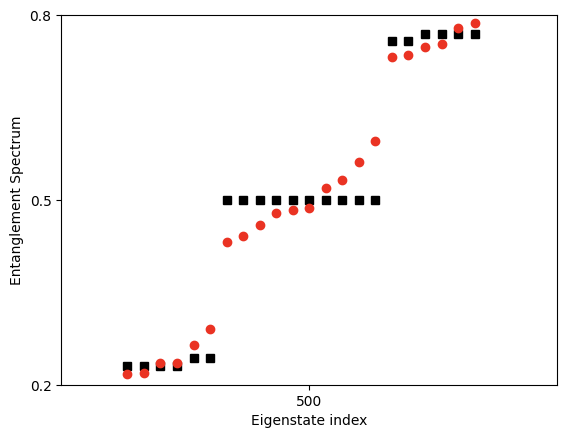

In [27]:
colorlist = ["#000000", "#EA3323"]
symbols = ["s", "o"]
for i, array in enumerate(quick_eigvals):
    plt.plot(array, symbols[i], color=colorlist[i])
# plt.title(f"w={w_array[i]:.2f}")
plt.ylim(0.2, 0.8)
plt.xlim(500-15, 500+15)
plt.yticks([0.2, 0.5, 0.8])
plt.xticks([500])
plt.xlabel("Eigenstate index")
plt.ylabel("Entanglement Spectrum")
plt.savefig("Figure1c.pdf", bbox_inches="tight")
plt.show()
plt.close()


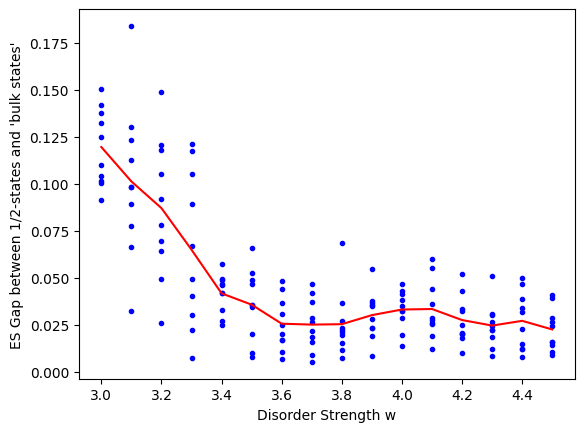

In [17]:
plt.plot(w_array, np.array(ES_gaps).reshape(w_array.shape[0], Ns), ".", color="blue")
plt.plot(w_array, np.mean(np.array(ES_gaps).reshape(w_array.shape[0], Ns), axis=1), color="red")
plt.ylabel("ES Gap between 1/2-states and 'bulk states'")
plt.xlabel("Disorder Strength w")
plt.show()

is projector: True


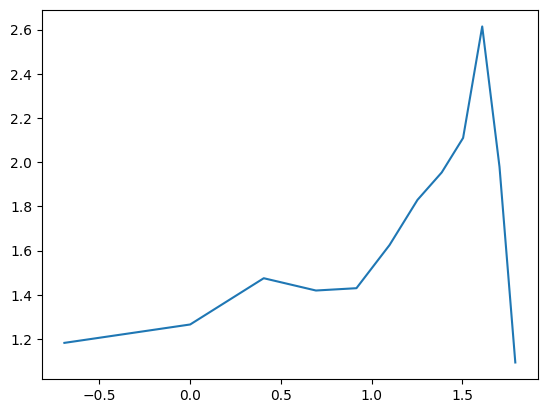

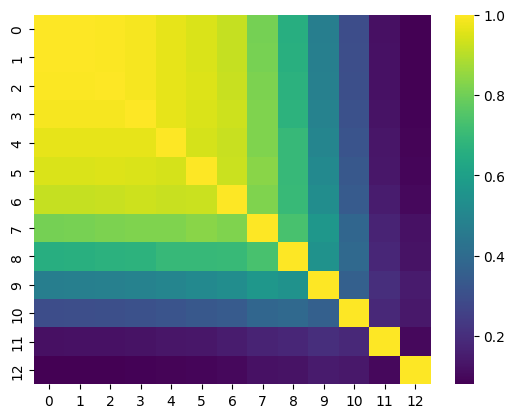

In [33]:
correlation_matrix = np.abs(np.einsum("ijk, mjk->im", np.array(all_combined_states).conj(), np.array(all_combined_states))**2/(np.outer(np.einsum("ijk, ijk->i", np.array(all_combined_states).conj(), np.array(all_combined_states)), np.einsum("ijk, ijk->i", np.array(all_combined_states).conj(), np.array(all_combined_states)))))
projector = all_combined_states[0]*10
print("is projector:", np.allclose(projector@projector, projector, atol=1e-10))
new_vals = []
for i in range(len(all_combined_states)):
    E, V = np.linalg.eigh(all_combined_states[i])
    # modified_combined_states.append(V[:, V.shape[1]-10:] @ V[:, V.shape[1]-10:].conj().T)
    new_vals.append(np.linalg.norm(projector@(np.eye(len(projector)) - V[:, V.shape[1]-100:] @ V[:, V.shape[1]-100:].conj().T)))

plt.plot(np.log(w_array[1:]), np.gradient(np.log(new_vals[1:]), np.log(w_array[1:])))
plt.show()

sns.heatmap(correlation_matrix, cmap='viridis')
plt.show()

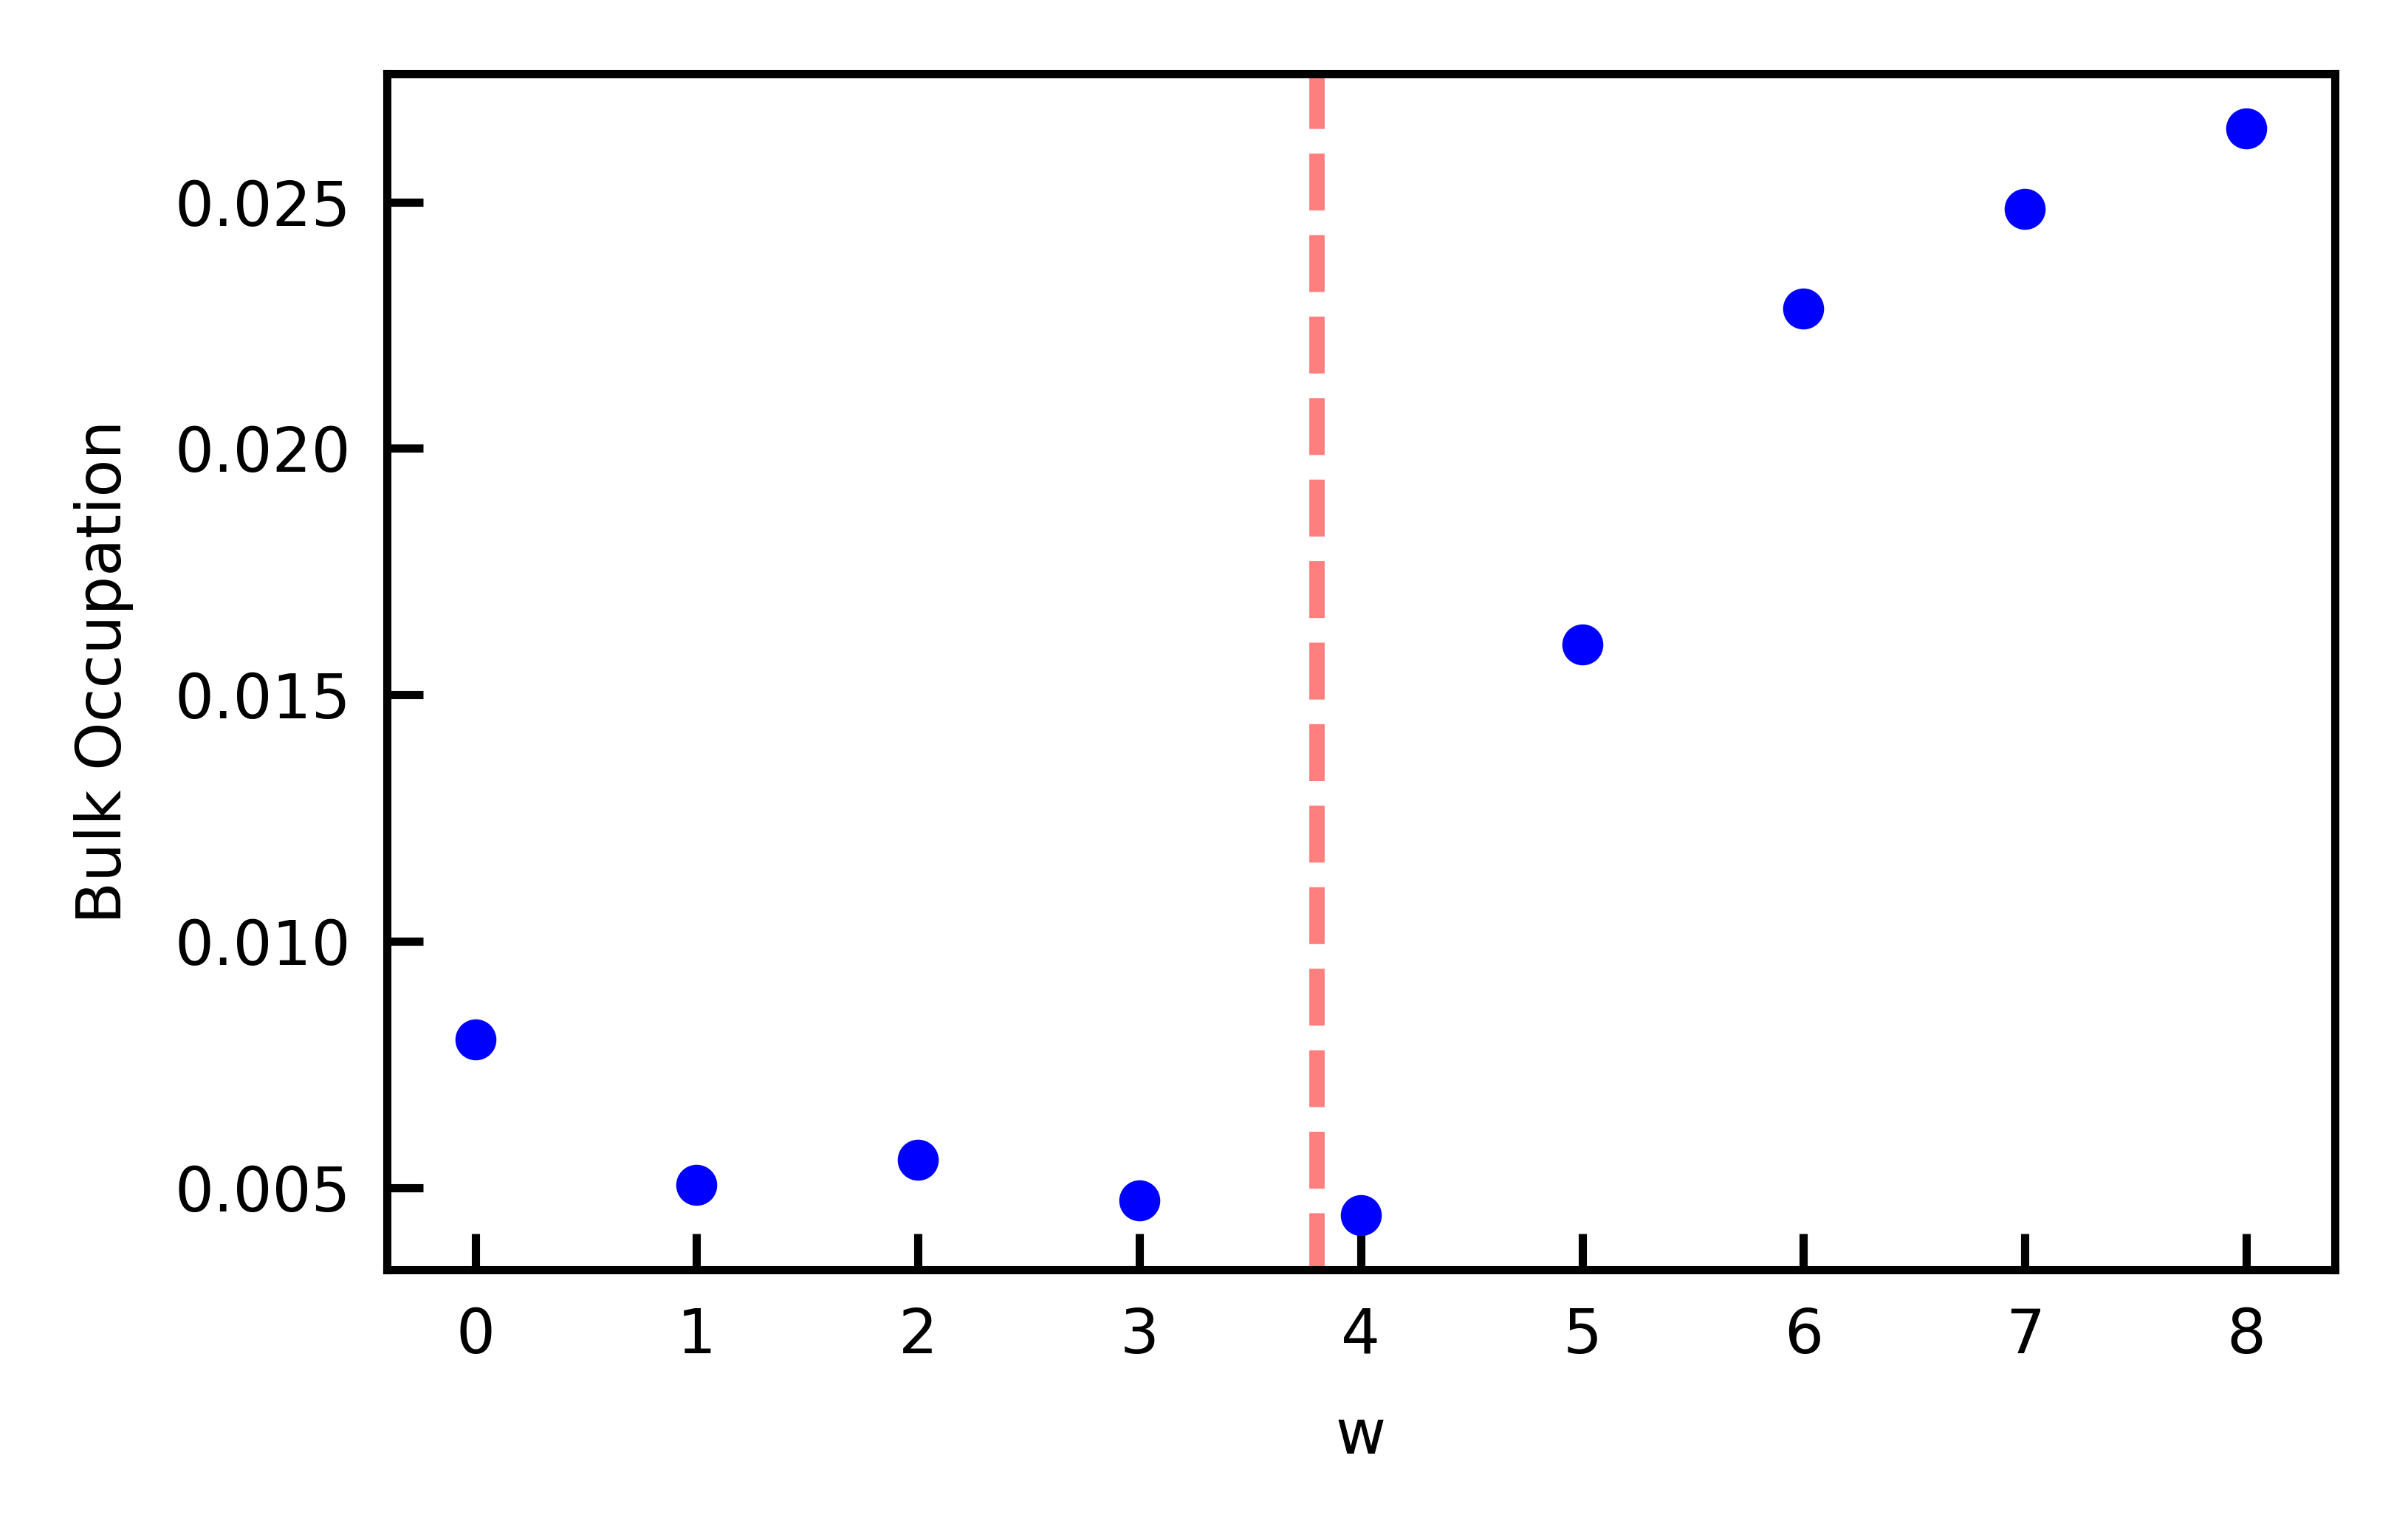

In [9]:
plt.plot(w_array, gaps, ".", color="blue")
plt.ylabel("Bulk Occupation")
plt.xlabel("w")
plt.axvline(3.8, linestyle="--", alpha=0.5, color="red")
plt.savefig("bulk_occupation.pdf", bbox_inches='tight')
plt.show()

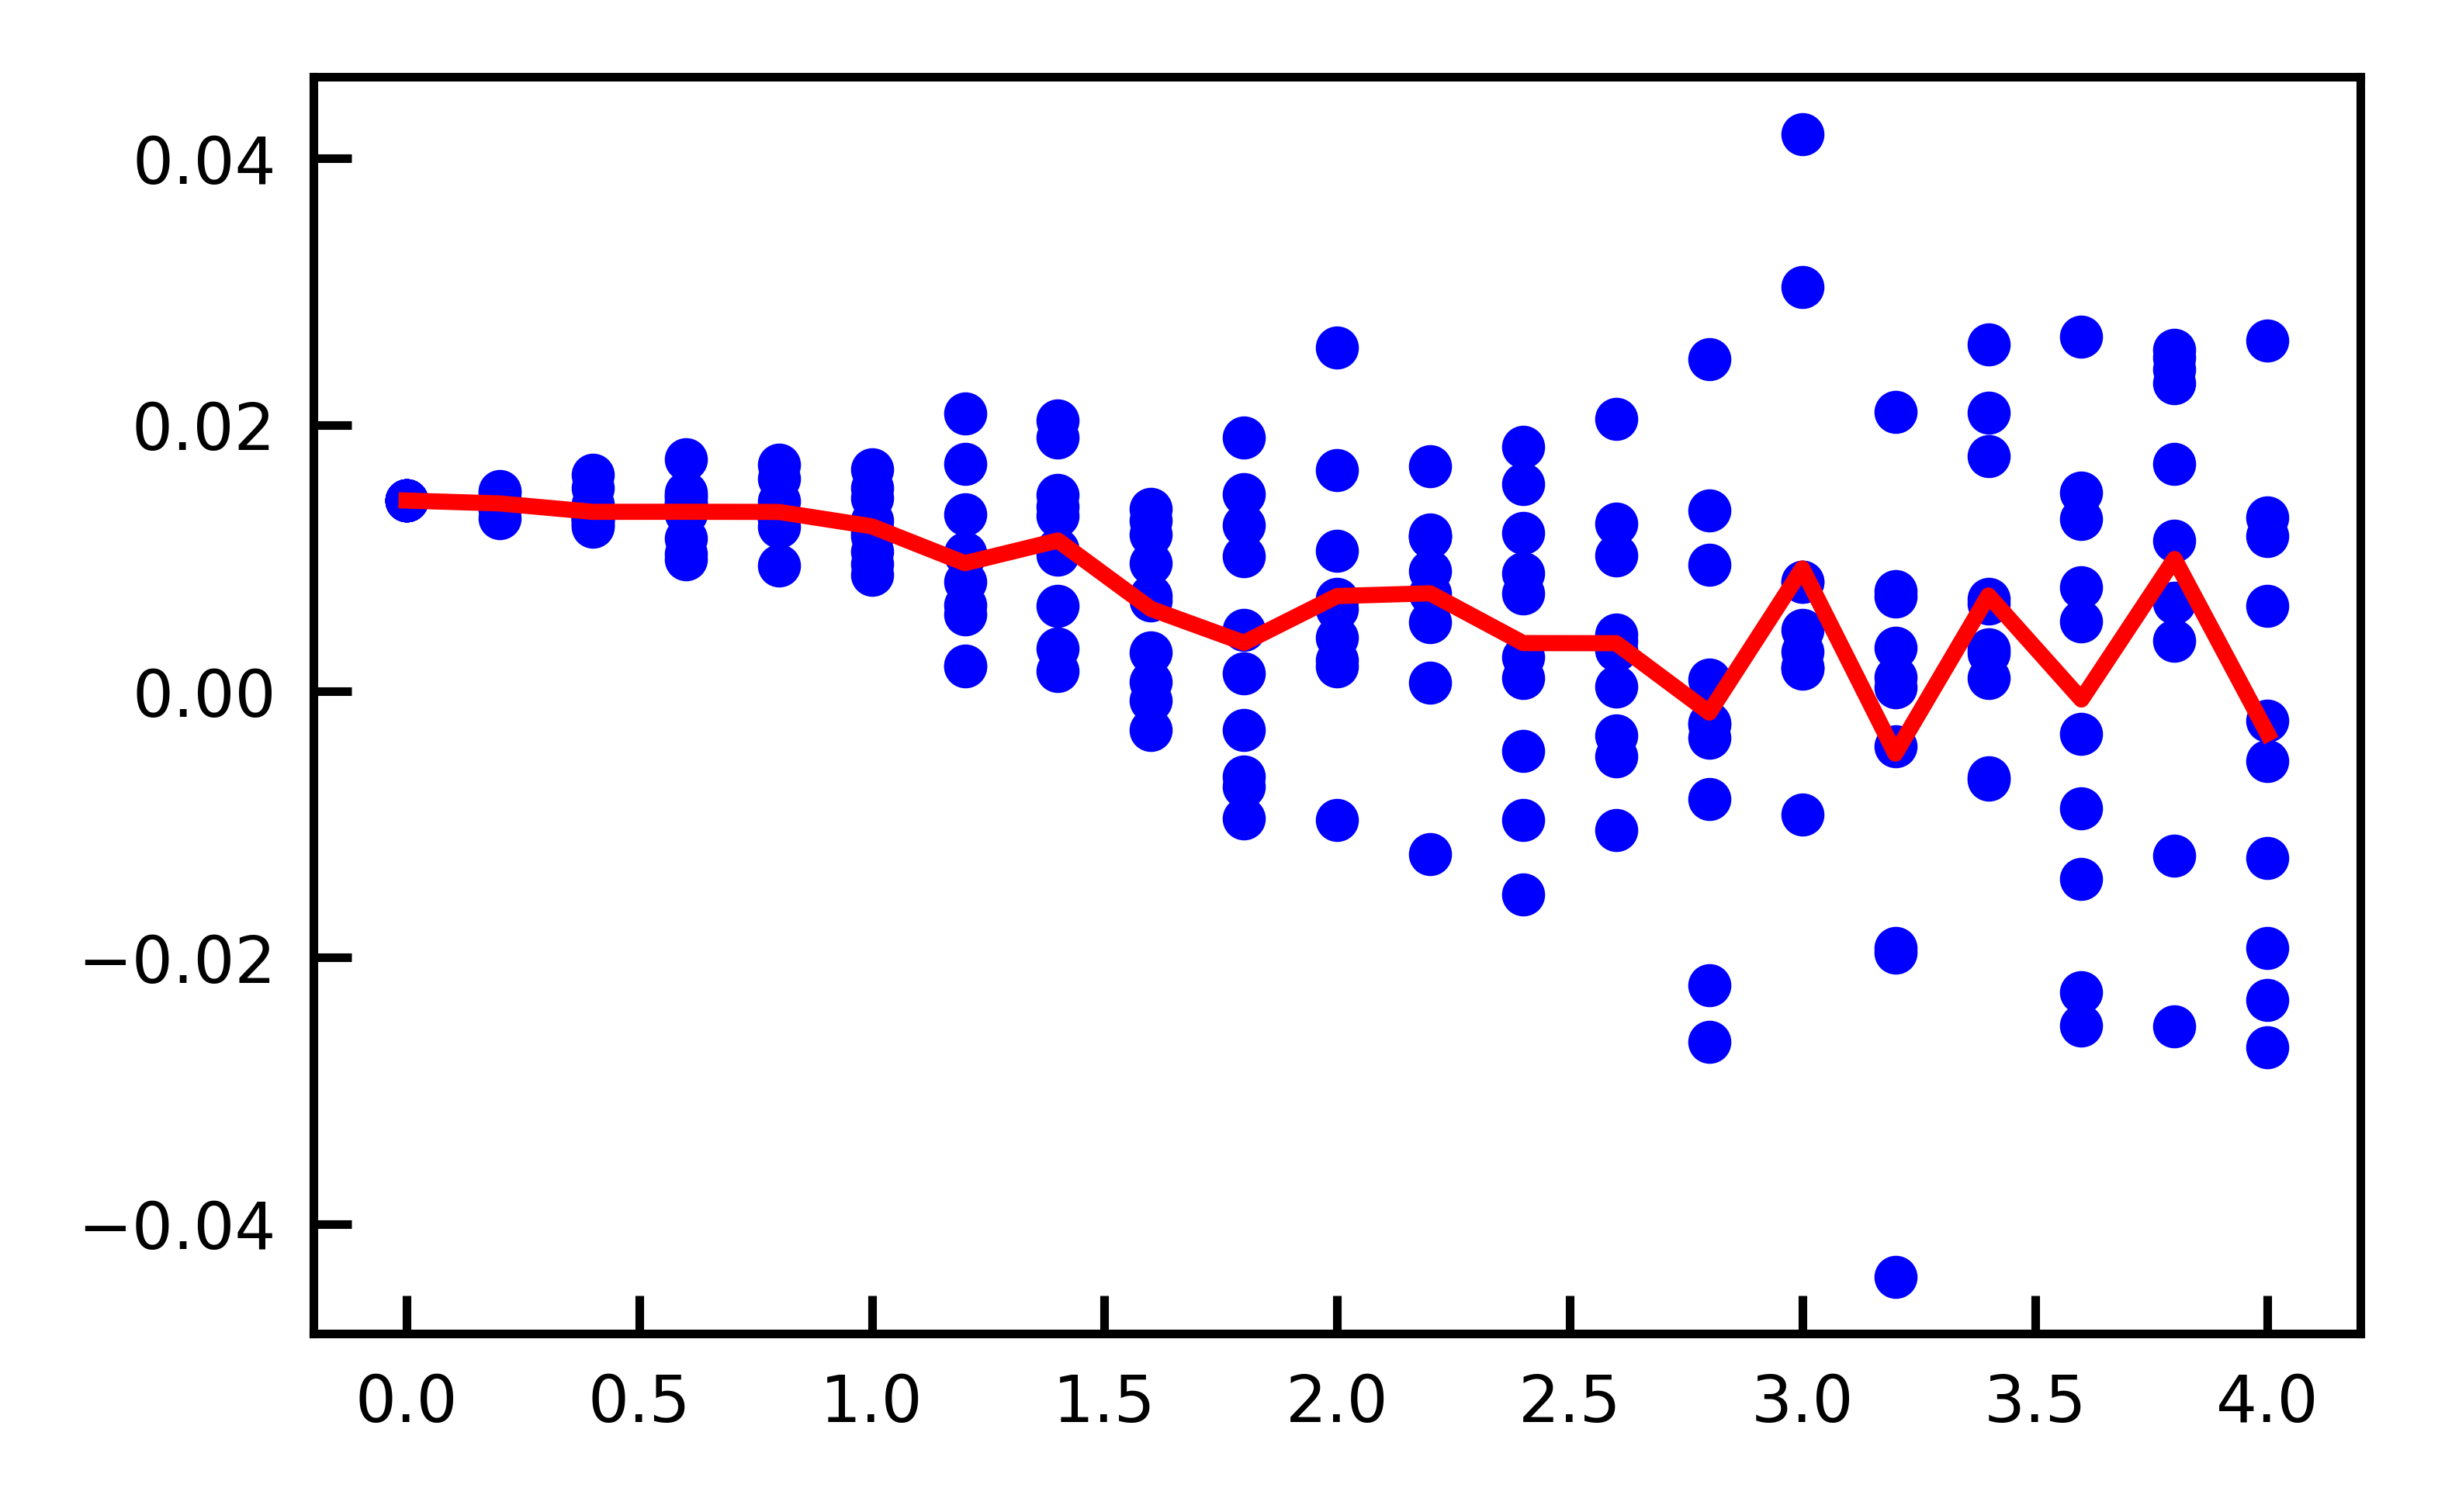

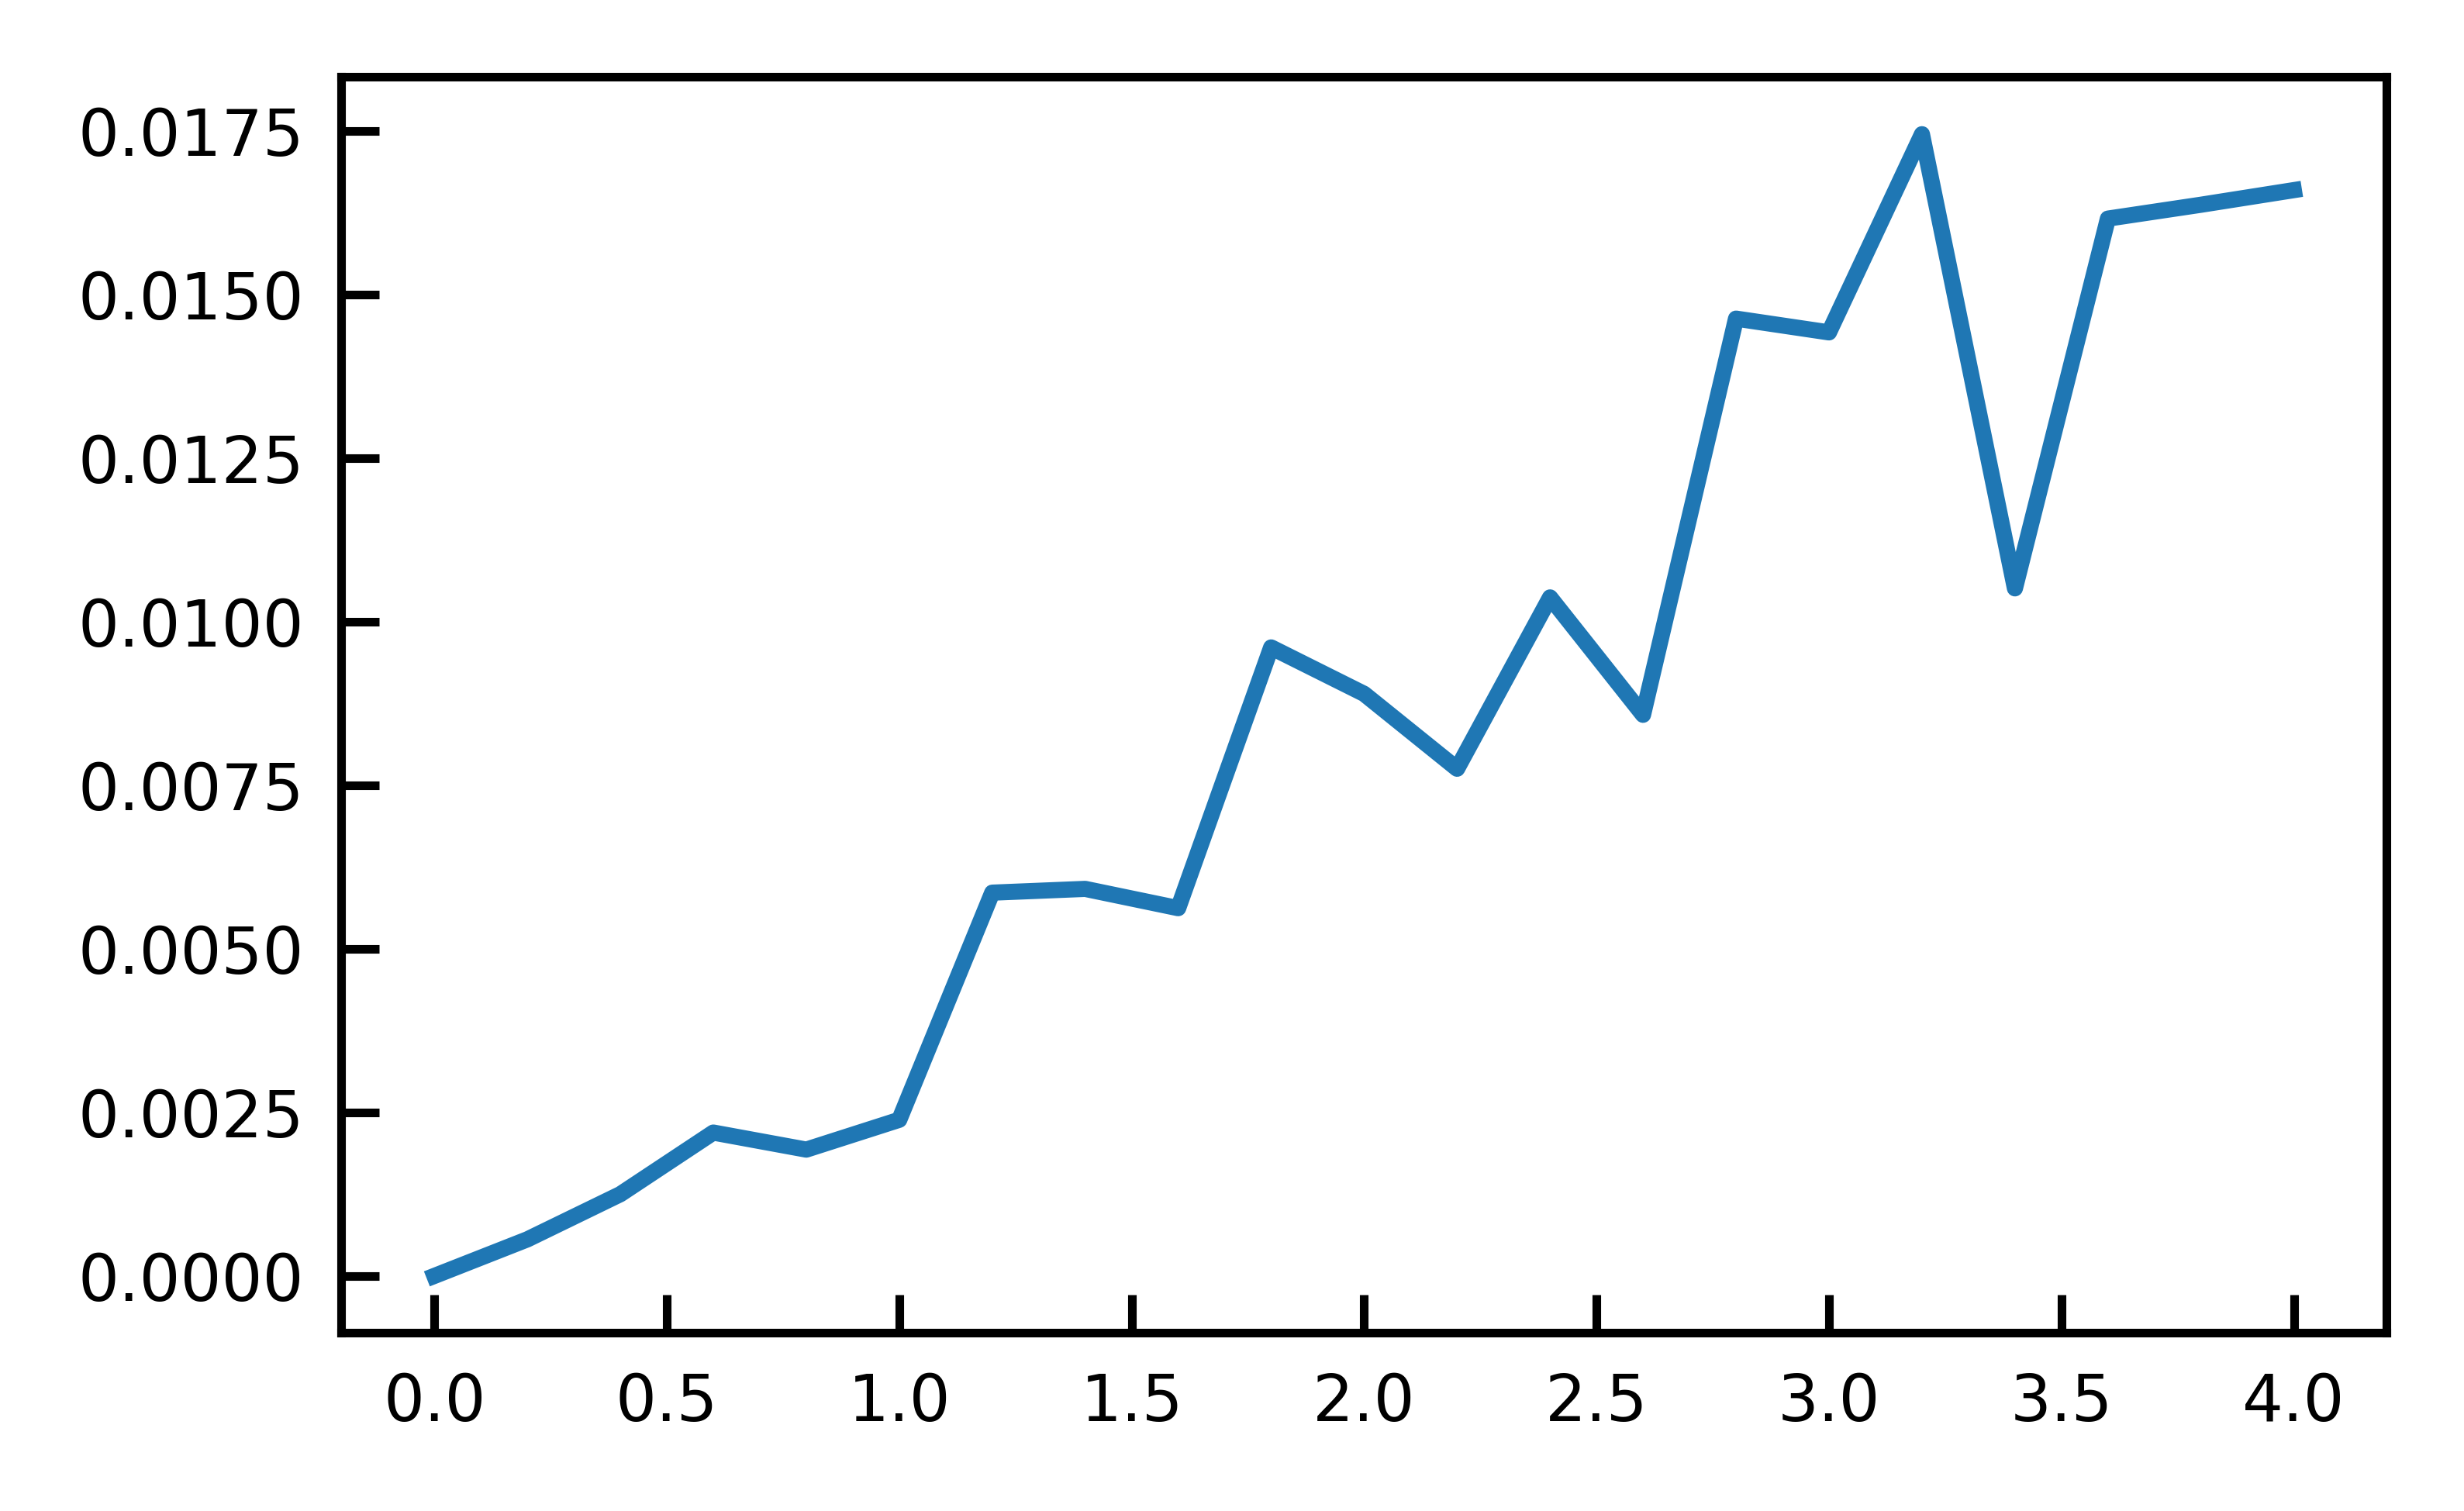

In [18]:
plt.plot(w_array, all_ent_diffs.T, ".", color="blue")
plt.plot(w_array, np.mean(all_ent_diffs, axis=0), color="red")
plt.show()
plt.plot(w_array, np.std(all_ent_diffs, axis=0))
plt.show()

In [ ]:
# Doing level spacing statistics
N = 4
L = [N]*3
t = 1.0
t_z = -1.0
m_z = 0.0
t_0 = 1.0
w = 0.0
disorder_type = "uniform"
Ns = 100
all_H = []
mz_array = np.arange(-4.0, 8.1, 0.1)
result = []
for i, mz in tqdm(enumerate(mz_array), total=len(mz_array)):
    result.append(fast_calc.get_all_entropies(L, t, t_z, mz, t_0, [0.0], 1, "uniform"))
result = np.array(result)
print(result.shape)
plt.plot(mz_array, result[:, 0], '.', label="PBC")
plt.xlabel(r'$m_z$')
plt.ylabel(r'Entropy $S$')
xlim_vals = (-5.0, 9.0)
plt.xlim(*xlim_vals)
plt.axvspan(xlim_vals[0], -1, color='#FBB4AE', alpha=0.3, label='Trivial Phase')
plt.axvspan(-1, 5, color='#B3CDE3', alpha=0.3, label='Topological Phase')
plt.axvspan(5, xlim_vals[1], color='#FBB4AE', alpha=0.3)
plt.legend(framealpha=1.0)
plt.savefig("entropy_vs_mz.pdf")
plt.close()